# Group 22 – Week 5: First Model Results

**Version 1.0** · **Task:** Group session week 5, item 4 – *"Have all the EDA, pre-processing and feature engineering done for your datasets. Have the results of one model."*

| Step | What this notebook does |
|---|---|
| 1 | Download the three datasets from Kaggle (same as week 4) |
| 2 | Rebuild the week 4 cleaned and feature datasets with the **unchanged** week 4 code (v1.3) |
| 3 | **Model 1 – M0 baseline (T09):** predict whether a stock goes up the next day from technical indicators – logistic regression vs a majority-class baseline |
| 4 | Model checks from the Test Plan (no data leakage, valid outputs) |
| 5 | **Model 2 (supports T10):** check FinBERT's sentiment labels on Financial PhraseBank against a simple TF-IDF baseline (Test Plan target ≥ 85%) |
| 6 | Save results for the log file and the README |

**Runtime:** CPU is enough for steps 1–4. For step 5 a GPU is faster (Runtime → Change runtime type → T4 GPU), but CPU also works (about 2–4 minutes).

## 1. Download the datasets
If Kaggle asks you to log in: Kaggle → Settings → API → Create New Token, then run `kagglehub.login()` in a new cell.

In [1]:
!pip -q install kagglehub
import kagglehub
price_dir = kagglehub.dataset_download("jacksoncrow/stock-market-dataset")
news_dir = kagglehub.dataset_download("miguelaenlle/massive-stock-news-analysis-db-for-nlpbacktests")
phrase_dir = kagglehub.dataset_download("ankurzing/sentiment-analysis-for-financial-news")
print(price_dir, news_dir, phrase_dir, sep="\n")

Using Colab cache for faster access to the 'stock-market-dataset' dataset.


100%|██████████| 210M/210M [00:10<00:00, 21.1MB/s]

Extracting files...


Using Colab cache for faster access to the 'sentiment-analysis-for-financial-news' dataset.
/kaggle/input/stock-market-dataset
/root/.cache/kagglehub/datasets/miguelaenlle/massive-stock-news-analysis-db-for-nlpbacktests/versions/2
/kaggle/input/sentiment-analysis-for-financial-news


In [2]:
import os, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", bbox_inches="tight", dpi=200); plt.show()

## 2. Rebuild the week 4 datasets
The two cells below are copied **unchanged** from the week 4 notebook (v1.3), so the model uses exactly the data that passed the 10 quality checks. Expected result: 30 stocks and 75,457 rows before the warm-up days are removed.

In [3]:
# CONFIG
N_STOCKS = 30
START, END = "2010-01-01", "2020-04-01"
TRAIN_END, VAL_END = "2017-12-31", "2018-12-31"
NOT_COMPANY_PATTERN = r"\bETNs?\b|Exchange[- ]Traded Notes?|\bNotes?\b|\bFund\b|VelocityShares|iPath|ProShares|Leveraged|Inverse"

import os, glob
import pandas as pd

def find(root, name):
    hits = glob.glob(os.path.join(root, "**", name), recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found under {root}")
    return hits[0]

def load_news(news_dir):
    parts = []
    for fname, text_col in [("raw_partner_headlines.csv", "headline"),
                            ("analyst_ratings_processed.csv", "title")]:
        try:
            df = pd.read_csv(find(news_dir, fname))
        except FileNotFoundError:
            continue
        df = df.rename(columns={text_col: "headline"})[["headline", "date", "stock"]]
        parts.append(df)
    news = pd.concat(parts, ignore_index=True).dropna()
    ts = pd.to_datetime(news["date"], errors="coerce", utc=True).dt.tz_convert("America/New_York")
    news = news[ts.notna()].copy()
    ts = ts[ts.notna()]
    # News after the 4pm close can only affect the NEXT trading day (avoids lookahead bias)
    day = ts.dt.normalize().dt.tz_localize(None)
    after_close = ts.dt.hour >= 16
    news["news_day"] = day + pd.to_timedelta(after_close.astype(int), unit="D")
    news["ticker"] = news["stock"].astype(str).str.upper().str.strip()
    news["headline"] = news["headline"].astype(str).str.strip()
    news = news.drop_duplicates(["ticker", "news_day", "headline"])
    return news[["ticker", "news_day", "headline"]]

def load_prices(price_dir, ticker):
    path = glob.glob(os.path.join(price_dir, "**", "stocks", f"{ticker}.csv"), recursive=True)
    if not path:
        return None
    p = pd.read_csv(path[0], parse_dates=["Date"])
    p = p.rename(columns={"Date": "date", "Open": "open", "High": "high", "Low": "low",
                          "Close": "close", "Adj Close": "adj_close", "Volume": "volume"})
    p = p[(p["date"] >= START) & (p["date"] < END)].sort_values("date").reset_index(drop=True)
    p["ticker"] = ticker
    return p

def build(price_dir, news_dir, out_path="combined_dataset.csv"):
    meta = pd.read_csv(find(price_dir, "symbols_valid_meta.csv"))
    names = dict(zip(meta["Symbol"], meta["Security Name"]))
    # Keep ordinary company shares only. Some ETNs (exchange-traded notes) and funds are marked
    # ETF = "N" in the meta file, so they are removed by name (found during week 4 EDA).
    not_company = meta["Security Name"].str.contains(NOT_COMPANY_PATTERN, case=False, regex=True, na=False)
    stock_symbols = set(meta.loc[(meta["ETF"] == "N") & ~not_company, "Symbol"])
    print(f"Removed {int(((meta['ETF'] == 'N') & not_company).sum())} ETNs/funds wrongly marked as stocks")

    news = load_news(news_dir)
    news = news[(news["news_day"] >= START) & (news["news_day"] < END)]
    news = news[news["ticker"].isin(stock_symbols)]

    # Pick the N stocks with the most headlines that also have price files
    chosen = []
    for t in news["ticker"].value_counts().index:
        prices = load_prices(price_dir, t)
        if prices is not None and len(prices) > 500:
            chosen.append(prices)
        if len(chosen) == N_STOCKS:
            break
    prices = pd.concat(chosen, ignore_index=True)

    # Remove bad price rows: missing values, prices <= 0, or high below low (data cleaning)
    price_cols = ["open", "high", "low", "close", "adj_close"]
    bad = (prices[price_cols + ["volume"]].isna().any(axis=1)
           | (prices[price_cols] <= 0).any(axis=1)
           | (prices["high"] < prices["low"])
           | (prices["volume"] < 0))
    print(f"Removed {int(bad.sum())} bad price rows (missing, zero/negative, or high < low)")
    if bad.any():
        print(prices.loc[bad, "ticker"].value_counts().to_string())
    prices = prices[~bad].reset_index(drop=True)

    # Remove repeated dates for the same stock (keep the first), and sort by date
    dup = prices.duplicated(["ticker", "date"])
    print(f"Removed {int(dup.sum())} repeated (ticker, date) rows")
    prices = prices[~dup].sort_values(["ticker", "date"]).reset_index(drop=True)
    tickers = prices["ticker"].unique()
    print(f"Chosen {len(tickers)} stocks:")
    for t in tickers:
        print(f"  {t:<6} {names.get(t, '')}")

    # Move each headline to the first trading day on or after its news_day
    news = news[news["ticker"].isin(tickers)].sort_values("news_day")
    trading_days = prices[["ticker", "date"]].sort_values("date")
    news = pd.merge_asof(news, trading_days, left_on="news_day", right_on="date",
                         by="ticker", direction="forward").dropna(subset=["date"])
    daily_news = (news.groupby(["ticker", "date"])["headline"]
                  .agg(n_headlines="count", headlines=lambda h: " || ".join(h))
                  .reset_index())

    df = prices.merge(daily_news, on=["ticker", "date"], how="left")
    df["n_headlines"] = df["n_headlines"].fillna(0).astype(int)
    df["headlines"] = df["headlines"].fillna("")
    df["company_name"] = df["ticker"].map(names)

    # Target: does tomorrow's close beat today's close? (1 = up, 0 = down/flat)
    df = df.sort_values(["ticker", "date"])
    next_close = df.groupby("ticker")["adj_close"].shift(-1)
    df["target_next_day_up"] = (next_close > df["adj_close"]).astype("Int64")
    df.loc[next_close.isna(), "target_next_day_up"] = pd.NA
    df = df.dropna(subset=["target_next_day_up"])

    # Time-based split (never random) to avoid lookahead
    df["split"] = "test"
    df.loc[df["date"] <= VAL_END, "split"] = "validation"
    df.loc[df["date"] <= TRAIN_END, "split"] = "train"

    cols = ["date", "ticker", "company_name", "open", "high", "low", "close", "adj_close",
            "volume", "n_headlines", "headlines", "target_next_day_up", "split"]
    df = df[cols].reset_index(drop=True)
    df.to_csv(out_path, index=False)
    print(f"Saved {out_path}: {len(df):,} rows, {df['ticker'].nunique()} stocks, "
          f"{df['date'].min().date()} to {df['date'].max().date()}")
    print(df["split"].value_counts().to_string())
    print("Share of days with news:", round((df["n_headlines"] > 0).mean(), 3))
    return df

In [4]:
import numpy as np
import pandas as pd

def add_rsi(df, window=14):
    """Relative Strength Index (Wilder's method), 0-100, using only past prices."""
    delta = df.groupby("ticker")["adj_close"].diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.groupby(df["ticker"]).transform(lambda s: s.ewm(alpha=1/window, adjust=False, min_periods=window).mean())
    avg_loss = loss.groupby(df["ticker"]).transform(lambda s: s.ewm(alpha=1/window, adjust=False, min_periods=window).mean())
    rs = avg_gain / avg_loss
    rsi = 100 - 100 / (1 + rs)
    rsi = rsi.where(avg_loss != 0, 100.0)          # no losses at all -> RSI = 100
    df["rsi_14"] = rsi.where(avg_gain.notna())
    return df

def add_macd(df, fast=12, slow=26, signal=9):
    """MACD line, signal line and histogram per ticker."""
    g = df.groupby("ticker")["adj_close"]
    ema_fast = g.transform(lambda s: s.ewm(span=fast, adjust=False).mean())
    ema_slow = g.transform(lambda s: s.ewm(span=slow, adjust=False).mean())
    df["macd"] = ema_fast - ema_slow
    df["macd_signal"] = df.groupby("ticker")["macd"].transform(lambda s: s.ewm(span=signal, adjust=False).mean())
    df["macd_hist"] = df["macd"] - df["macd_signal"]
    return df

def add_bollinger(df, window=20, n_std=2):
    """Bollinger Bands; %B shows where the price sits inside the band (0 = lower, 1 = upper)."""
    g = df.groupby("ticker")["adj_close"]
    mid = g.transform(lambda s: s.rolling(window).mean())
    std = g.transform(lambda s: s.rolling(window).std())
    df["bb_upper"] = mid + n_std * std
    df["bb_lower"] = mid - n_std * std
    df["bb_pct_b"] = (df["adj_close"] - df["bb_lower"]) / (df["bb_upper"] - df["bb_lower"])
    return df

def add_moving_average_ratios(df, windows=(5, 20, 50)):
    """Price divided by its moving average (above 1 = price above its average)."""
    g = df.groupby("ticker")["adj_close"]
    for w in windows:
        df[f"ma_ratio_{w}"] = df["adj_close"] / g.transform(lambda s: s.rolling(w).mean())
    return df

def add_returns(df):
    df["return_1d"] = df.groupby("ticker")["adj_close"].pct_change()
    return df

def build_features(df):
    """Add all technical features. Every value on day t uses only data up to day t."""
    df = df.sort_values(["ticker", "date"]).reset_index(drop=True)
    for step in (add_returns, add_rsi, add_macd, add_bollinger, add_moving_average_ratios):
        df = step(df)
    return df

FEATURE_COLS = ["return_1d", "rsi_14", "macd", "macd_signal", "macd_hist",
                "bb_upper", "bb_lower", "bb_pct_b", "ma_ratio_5", "ma_ratio_20", "ma_ratio_50", "n_headlines"]

In [5]:
df = build(price_dir, news_dir, "combined_dataset.csv")
feat = build_features(df)
feat = feat.dropna(subset=[c for c in FEATURE_COLS if c != "n_headlines"])   # warm-up days, as in week 4
print(f"Feature dataset: {len(feat):,} rows, {feat['ticker'].nunique()} stocks")
print(feat["split"].value_counts().reindex(["train", "validation", "test"]).to_string())

Removed 604 ETNs/funds wrongly marked as stocks
Removed 1 bad price rows (missing, zero/negative, or high < low)
ticker
TXN    1
Removed 0 repeated (ticker, date) rows
Chosen 30 stocks:
  ALK    Alaska Air Group, Inc. Common Stock
  AVGO   Broadcom Inc. - Common Stock
  BLK    BlackRock, Inc. Common Stock
  CI     Cigna Corporation Common Stock
  CSX    CSX Corporation - Common Stock
  D      Dominion Energy, Inc. Common Stock
  DISH   DISH Network Corporation - Class A Common Stock
  DUK    Duke Energy Corporation (Holding Company) Common Stock
  FCAU   Fiat Chrysler Automobiles N.V. Common Shares
  FCX    Freeport-McMoRan, Inc. Common Stock
  INTC   Intel Corporation - Common Stock
  JD     JD.com, Inc. - American Depositary Shares
  JPM    JP Morgan Chase & Co. Common Stock
  JWN    Nordstrom, Inc. Common Stock
  KEY    KeyCorp Common Stock
  KR     Kroger Company (The) Common Stock
  LEN    Lennar Corporation Class A Common Stock
  MDT    Medtronic plc. Ordinary Shares
  MYL    Myl

## 3. Model 1 (T09): next-day direction from technical indicators
**Question:** from today's indicators, will the stock close higher tomorrow (1) or not (0)?

- **Baseline:** always predict the most common class in the training years. Any useful model must beat this.
- **Model:** logistic regression on scaled features, called **M0** in the Test Plan. It is simple, fast and easy to explain, so it is the benchmark that the planned models (M1 Bi-LSTM, M2 FinBERT, M3 Hybrid) must beat.
- **Features:** the week 4 indicators. MACD and Bollinger values are in dollars, so they are divided by the price to make stocks comparable.
- **No look-ahead:** the regularisation strength *C* is chosen on the **2018 validation year**; the **2019–2020 test years are used only once**, at the end.
- **KPIs (Test Plan section 5):** directional accuracy ≥ 56%, precision on BUY ("up") signals ≥ 60%, ROC-AUC ≥ 0.60.

In [6]:
# Model 1: next-day direction (task T09)
import json
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

KPIS = {"accuracy": 0.56, "precision": 0.60, "roc_auc": 0.60}   # targets from the Project Specifications / Test Plan
KPI_ACCURACY = KPIS["accuracy"]

def add_scale_free_features(df):
    """MACD and Bollinger levels are in dollars, so they cannot be compared across stocks.
    Divide them by the price so every stock is on the same scale."""
    df = df.copy()
    for c in ("macd", "macd_signal", "macd_hist"):
        df[f"{c}_pct"] = df[c] / df["adj_close"]
    df["bb_width_pct"] = (df["bb_upper"] - df["bb_lower"]) / df["adj_close"]
    df["has_news"] = (df["n_headlines"] > 0).astype(int)
    return df

MODEL_FEATURES = ["return_1d", "rsi_14", "macd_pct", "macd_signal_pct", "macd_hist_pct",
                  "bb_pct_b", "bb_width_pct", "ma_ratio_5", "ma_ratio_20", "ma_ratio_50",
                  "n_headlines", "has_news"]

def split_xy(df, split):
    part = df[df["split"] == split]
    return part[MODEL_FEATURES], part["target_next_day_up"].astype(int)

def evaluate(y_true, y_pred, y_score=None):
    out = {"accuracy": accuracy_score(y_true, y_pred),
           "precision": precision_score(y_true, y_pred, zero_division=0),
           "recall": recall_score(y_true, y_pred, zero_division=0),
           "f1": f1_score(y_true, y_pred, zero_division=0)}
    out["roc_auc"] = roc_auc_score(y_true, y_score) if y_score is not None else None
    return {k: (round(float(v), 4) if v is not None else None) for k, v in out.items()}

def run_direction_model(feat, c_values=(0.001, 0.01, 0.1, 1.0, 10.0)):
    """Logistic regression on technical features. C is chosen on the 2018 validation year;
    the 2019-2020 test years are used once, at the end."""
    df = add_scale_free_features(feat).replace([np.inf, -np.inf], np.nan).dropna(subset=MODEL_FEATURES)
    X_tr, y_tr = split_xy(df, "train")
    X_va, y_va = split_xy(df, "validation")
    X_te, y_te = split_xy(df, "test")

    # Baseline: always predict the most common class in the training data
    majority = int(y_tr.mean() >= 0.5)
    baseline = evaluate(y_te, np.full(len(y_te), majority))

    tuning = []
    for c in c_values:
        m = make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=1000))
        m.fit(X_tr, y_tr)
        tuning.append({"C": c, "val_accuracy": round(accuracy_score(y_va, m.predict(X_va)), 4)})
    best_c = max(tuning, key=lambda r: r["val_accuracy"])["C"]

    # Final model: refit on train + validation with the chosen C, test once
    model = make_pipeline(StandardScaler(), LogisticRegression(C=best_c, max_iter=1000))
    model.fit(pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va]))
    pred = model.predict(X_te)
    score = model.predict_proba(X_te)[:, 1]
    results = {"model": "M0 baseline: logistic regression (scaled technical features)", "best_C": best_c,
               "rows": {"train": len(X_tr), "validation": len(X_va), "test": len(X_te)},
               "test_up_share": round(float(y_te.mean()), 4),
               "baseline_majority_class": {"predicts": "up" if majority else "down", **baseline},
               "logistic_regression": evaluate(y_te, pred, score),
               "tuning": tuning, "kpi_accuracy": KPI_ACCURACY}
    results["kpi_check"] = {k: {"target": t, "result": results["logistic_regression"][k],
                                "pass": results["logistic_regression"][k] >= t} for k, t in KPIS.items()}
    results["meets_kpi"] = results["logistic_regression"]["accuracy"] >= KPI_ACCURACY
    results["beats_baseline"] = results["logistic_regression"]["accuracy"] > baseline["accuracy"]
    coefs = model.named_steps["logisticregression"].coef_[0]
    importance = pd.Series(coefs, index=MODEL_FEATURES).sort_values(key=abs, ascending=False)
    cm = confusion_matrix(y_te, pred, labels=[0, 1])
    return results, importance, cm, df

In [7]:
direction, importance, cm, model_df = run_direction_model(feat)
lr, base = direction["logistic_regression"], direction["baseline_majority_class"]
print("Rows:", direction["rows"], "| share of up days in test:", direction["test_up_share"])
print("Validation accuracy for each C:", direction["tuning"], "-> chosen C =", direction["best_C"])
table = pd.DataFrame({"Baseline (always '" + base["predicts"] + "')": base, "Logistic regression": lr}).drop("predicts")
print(table.T.to_string())
print(f"\nBeats baseline: {direction['beats_baseline']}")
print(pd.DataFrame(direction["kpi_check"]).T.to_string())

Rows: {'train': 57067, 'validation': 7530, 'test': 9390} | share of up days in test: 0.5243
Validation accuracy for each C: [{'C': 0.001, 'val_accuracy': 0.4985}, {'C': 0.01, 'val_accuracy': 0.4963}, {'C': 0.1, 'val_accuracy': 0.498}, {'C': 1.0, 'val_accuracy': 0.4981}, {'C': 10.0, 'val_accuracy': 0.498}] -> chosen C = 0.001
                       accuracy precision  recall      f1 roc_auc
Baseline (always 'up')   0.5243    0.5243     1.0  0.6879    None
Logistic regression      0.5308    0.5346  0.8121  0.6447  0.5209

Beats baseline: True
          target  result   pass
accuracy    0.56  0.5308  False
precision    0.6  0.5346  False
roc_auc      0.6  0.5209  False


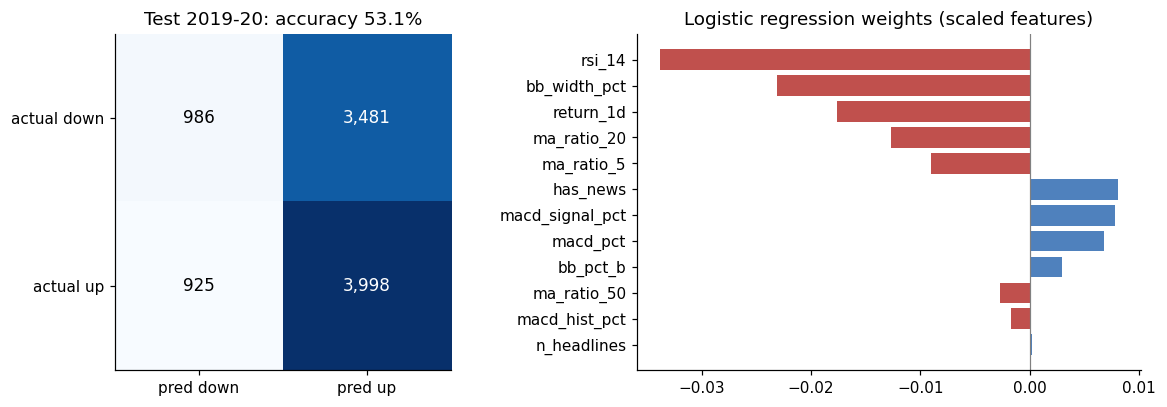

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[0].text(j, i, f"{v:,}", ha="center", va="center", fontsize=11, color="white" if v > cm.max() / 2 else "black")
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["pred down", "pred up"])
ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["actual down", "actual up"])
ax[0].set_title(f"Test 2019-20: accuracy {lr['accuracy']:.1%}")
imp = importance.iloc[::-1]
ax[1].barh(imp.index, imp.values, color=np.where(imp.values >= 0, "#4F81BD", "#C0504D"))
ax[1].axvline(0, c="grey", lw=0.8); ax[1].set_title("Logistic regression weights (scaled features)")
save("05_direction_model_results")

**How to read this:** stock direction is close to a coin toss (about 51% up days), so accuracy only slightly above the baseline is normal for a first model using prices alone. Compare the model with the baseline and the three KPIs, and look at **ROC-AUC** (0.5 = no skill). Missing a KPI with the first model is expected; the result is recorded honestly in the Test Plan KPI table. The next steps are adding FinBERT news sentiment as a feature (T10) and trying a non-linear model.

## 4. Model checks (from the Test Plan)
If any check fails, this cell stops with an error so problems are never hidden.

In [9]:
def run_model_checks(model_df, direction, rerun):
    results = []
    def check(name, ok, detail=""):
        results.append((name, "PASS" if ok else "FAIL", detail))
    d = {s: model_df.loc[model_df["split"] == s, "date"] for s in ("train", "validation", "test")}
    check("No leakage: train dates before validation dates", d["train"].max() < d["validation"].min(),
          f"{d['train'].max().date()} < {d['validation'].min().date()}")
    check("No leakage: validation dates before test dates", d["validation"].max() < d["test"].min(),
          f"{d['validation'].max().date()} < {d['test'].min().date()}")
    check("Inputs: no missing or infinite feature values", np.isfinite(model_df[MODEL_FEATURES].to_numpy()).all())
    check("Target: only 0 and 1", set(model_df["target_next_day_up"].astype(int).unique()) <= {0, 1})
    check("Rows: train + validation + test = all model rows", sum(direction["rows"].values()) == len(model_df))
    m = direction["logistic_regression"]
    check("Outputs: metrics between 0 and 1", all(0 <= v <= 1 for v in m.values() if v is not None))
    check("Reproducible: same accuracy when run again", rerun["logistic_regression"]["accuracy"] == m["accuracy"])
    table = pd.DataFrame(results, columns=["check", "result", "detail"])
    print(table.to_string(index=False))
    failed = table[table["result"] == "FAIL"]
    if len(failed):
        raise AssertionError(f"{len(failed)} model check(s) failed: {list(failed['check'])}")
    print(f"\nAll {len(table)} model checks passed.")
    return table

rerun, *_ = run_direction_model(feat)
model_checks = run_model_checks(model_df, direction, rerun)
model_checks.to_csv("results/model_checks.csv", index=False)

                                           check result                  detail
 No leakage: train dates before validation dates   PASS 2017-12-29 < 2018-01-02
  No leakage: validation dates before test dates   PASS 2018-12-31 < 2019-01-02
   Inputs: no missing or infinite feature values   PASS                        
                            Target: only 0 and 1   PASS                        
Rows: train + validation + test = all model rows   PASS                        
                Outputs: metrics between 0 and 1   PASS                        
      Reproducible: same accuracy when run again   PASS                        

All 7 model checks passed.


## 5. Model 2 (supports T10): checking FinBERT's sentiment labels
Before FinBERT scores are added to the trading data (T10), we check how well it labels financial sentences. Financial PhraseBank has the correct label for every sentence, so we can measure this.

- The sentences are split 80/20 (stratified, fixed seed). Sentences are not a time series, so a random split is fine here.
- **Baseline:** TF-IDF word features + logistic regression, trained on the 80%.
- **FinBERT** (`ProsusAI/finbert`, Araci 2019 – our Paper 1) is used as it is, with no extra training, on the same 20%.
- **Important caveat:** FinBERT was originally fine-tuned on Financial PhraseBank, so some test sentences may have been in its training data. Its score here is probably **optimistic**, and the real test is on our news headlines.

In [10]:
# Model 2: news sentiment check (supports task T10)
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

LABELS = ["negative", "neutral", "positive"]
FINBERT_TARGET = 0.85       # Test Plan section 5: FinBERT accuracy on Financial PhraseBank

def load_phrasebank(path):
    pb = pd.read_csv(path, header=None, names=["sentiment", "headline"], encoding="latin-1")
    pb["headline"] = pb["headline"].astype(str).str.strip()
    return pb[~pb["headline"].duplicated()].reset_index(drop=True)      # same cleaning as week 4

def split_phrasebank(pb, test_size=0.2, seed=42):
    """Sentences are not a time series, so a stratified random split is fine here."""
    return train_test_split(pb, test_size=test_size, random_state=seed, stratify=pb["sentiment"])

def sentiment_scores(y_true, y_pred):
    return {"accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
            "macro_f1": round(float(f1_score(y_true, y_pred, average="macro", labels=LABELS)), 4)}

def run_tfidf_baseline(train, test):
    model = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                          LogisticRegression(max_iter=2000, class_weight="balanced"))
    model.fit(train["headline"], train["sentiment"])
    pred = model.predict(test["headline"])
    return pred, sentiment_scores(test["sentiment"], pred)

def run_finbert(test, classifier, batch_size=32):
    """`classifier` is a Hugging Face pipeline for ProsusAI/finbert (labels: positive/negative/neutral)."""
    out = classifier(list(test["headline"]), batch_size=batch_size, truncation=True)
    pred = [o["label"].lower() for o in out]
    unknown = set(pred) - set(LABELS)
    assert not unknown, f"Unexpected FinBERT labels: {unknown}"
    return pred, sentiment_scores(test["sentiment"], pred)

def sentiment_confusion(y_true, y_pred):
    return pd.DataFrame(confusion_matrix(y_true, y_pred, labels=LABELS),
                        index=[f"true {l}" for l in LABELS], columns=[f"pred {l}" for l in LABELS])

In [11]:
pb = load_phrasebank(glob.glob(os.path.join(phrase_dir, "**", "all-data.csv"), recursive=True)[0])
pb_train, pb_test = split_phrasebank(pb)
print(f"PhraseBank: {len(pb):,} sentences -> train {len(pb_train):,} / test {len(pb_test):,}")
tfidf_pred, tfidf_scores = run_tfidf_baseline(pb_train, pb_test)
print("TF-IDF baseline:", tfidf_scores)

PhraseBank: 4,838 sentences -> train 3,870 / test 968
TF-IDF baseline: {'accuracy': 0.7521, 'macro_f1': 0.7145}


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

FinBERT: {'accuracy': 0.875, 'macro_f1': 0.8668} | Test Plan target 85%: PASS
                              accuracy  macro_f1
TF-IDF + logistic regression    0.7521    0.7145
FinBERT (no extra training)     0.8750    0.8668


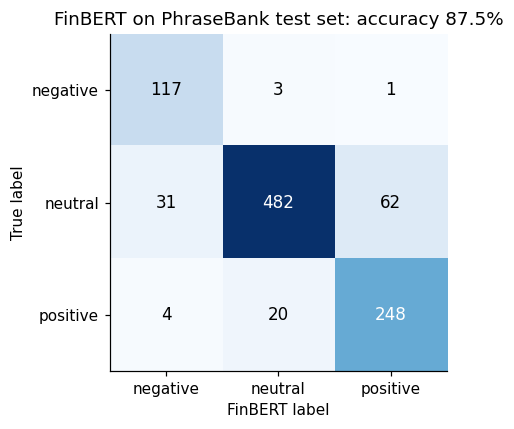

In [12]:
import torch
from transformers import pipeline
finbert = pipeline("text-classification", model="ProsusAI/finbert", device=0 if torch.cuda.is_available() else -1)
finbert_pred, finbert_scores = run_finbert(pb_test, finbert)
print("FinBERT:", finbert_scores, "| Test Plan target 85%:", "PASS" if finbert_scores["accuracy"] >= FINBERT_TARGET else "FAIL")
sentiment_table = pd.DataFrame({"TF-IDF + logistic regression": tfidf_scores, "FinBERT (no extra training)": finbert_scores}).T
print(sentiment_table.to_string())

cm_fin = sentiment_confusion(pb_test["sentiment"], finbert_pred)
fig, ax = plt.subplots(figsize=(5.2, 4))
ax.imshow(cm_fin.values, cmap="Blues")
for (i, j), v in np.ndenumerate(cm_fin.values):
    ax.text(j, i, v, ha="center", va="center", fontsize=11, color="white" if v > cm_fin.values.max() / 2 else "black")
ax.set_xticks(range(3)); ax.set_xticklabels(LABELS); ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
ax.set_xlabel("FinBERT label"); ax.set_ylabel("True label")
ax.set_title(f"FinBERT on PhraseBank test set: accuracy {finbert_scores['accuracy']:.1%}")
save("06_finbert_confusion_matrix")

## 6. Save the results

In [13]:
results = {"date_run": pd.Timestamp.today().strftime("%Y-%m-%d"),
           "model_1_direction": direction,
           "model_1_top_features": importance.round(4).to_dict(),
           "model_2_sentiment": {"test_sentences": len(pb_test), "tfidf_baseline": tfidf_scores,
                                 "finbert": finbert_scores}}
with open("results/week5_model_results.json", "w") as f:
    json.dump(results, f, indent=2, default=str)
print("Saved: results/week5_model_results.json, results/model_checks.csv, figures/05_*.png, figures/06_*.png")
print(f"\nModel 1 test accuracy {lr['accuracy']:.1%} (baseline {base['accuracy']:.1%}, KPI 56%), ROC-AUC {lr['roc_auc']}")
print(f"Model 2 FinBERT accuracy {finbert_scores['accuracy']:.1%} vs TF-IDF {tfidf_scores['accuracy']:.1%}")
# To download in Colab:
# from google.colab import files
# for f in ["results/week5_model_results.json", "results/model_checks.csv",
#           "figures/05_direction_model_results.png", "figures/06_finbert_confusion_matrix.png"]: files.download(f)

Saved: results/week5_model_results.json, results/model_checks.csv, figures/05_*.png, figures/06_*.png

Model 1 test accuracy 53.1% (baseline 52.4%, KPI 56%), ROC-AUC 0.5209
Model 2 FinBERT accuracy 87.5% vs TF-IDF 75.2%


## Summary for the log file
- Rebuilt the week 4 datasets with the unchanged v1.3 code
- **Model 1 (T09):** logistic regression predicting next-day direction from technical indicators, tuned on 2018 and tested once on 2019–2020, compared with a majority-class baseline and the 56% KPI
- Ran the model checks from the Test Plan (no leakage, valid inputs and outputs, reproducible)
- **Model 2 (supports T10):** FinBERT's sentiment labels checked on Financial PhraseBank against a TF-IDF baseline
- **Next:** add daily FinBERT sentiment of the headlines as features (T10) and compare Model 1 with and without sentiment